# 01 · 固定网格 MLP 解 Poisson 方程（初级）

**前置：** 00 和 PyTorch 张量。**目标：** 跑通采样、训练、验证、测试的完整流程，理解固定维度网络的限制。

继续解 $-u''=f$，零 Dirichlet 边界。将 33 个输入采样值映射到 33 个输出采样值，这是神经算子的**有限维基线**。它不能直接处理不同长度网格。训练输出为 $v=\pi^2u$，评估时恢复 $u$。

## 原理详解 A：MLP 基线究竟学到了什么？

### A.1 网格上的线性解算子

对固定网格，有限差分方程是 $\mathbf u=A_h^{-1}\mathbf f$。若使用本章的解析标签，则目标是连续解的采样，而不是严格的 $A_h^{-1}$；但在本章有限正弦函数族上，输入到输出仍可由某个线性映射表达。

MLP 计算
$$
\mathbf z_1=\tanh(W_1\mathbf f+\mathbf b_1),\quad
\mathbf z_2=\tanh(W_2\mathbf z_1+\mathbf b_2),\quad
\widetilde{\mathbf v}=W_3\mathbf z_2+\mathbf b_3.
$$
每个输出都可依赖全部输入位置，因此它能表达非局部关系。尽管 PDE 是线性的，我们使用非线性网络是为了熟悉通用训练流程；纯线性层也是合理且更简单的对照。

### A.2 为什么不能直接改变输入网格？

本章维度为 $33\rightarrow64\rightarrow64\rightarrow33$，参数总数是
$$
(33\cdot64+64)+(64\cdot64+64)+(64\cdot33+33)=8481.
$$
换成 65 个输入点，第一层的 33 列权重无法与长度 65 的输入相乘。换输出点数，则最后一层也必须重建。输入插值到 33 点可避免 shape 错误，但那是额外的数据处理，并没有改变网络固定网格的本质。

### A.3 本章真正测试的泛化范围

训练 forcing 来自前 5 个正弦模式，网络看到的 33 维输入实际上位于一个低维函数族中。测试同分布新系数，测的是这个函数族中的新实例泛化；增加到 10 个模式，则离开原来的训练输入子空间。即使 PDE 本身没变，网络也未必识别新模式。

## 原理详解 B：硬边界约束为何有效？

令
$$
v_\theta(x)=d(x)\widetilde v_\theta(x),\qquad d(x)=4x(1-x).
$$
由于 $d(0)=d(1)=0$，任意网络参数都满足端点条件。本章是在离散输出上逐点乘以这个因子，因此准确保证采样端点为零，不自动保证内部满足微分方程。

硬约束相当于把模型搜索空间缩小到满足边界的一类函数。对于本章光滑解，通常可把边界附近的线性消失行为交给 $d(x)$ 表达。若真解在边界有奇异行为，或者改变边界类型，因子需要重新设计。

非零 Dirichlet 条件 $u(0)=g_0,u(1)=g_1$ 可用
$$
u_\theta(x)=(1-x)g_0+xg_1+x(1-x)w_\theta(x)
$$
表达。若边界值随样本变化，还要把 $g_0,g_1$ 作为输入，不能仅在输出端固定一组数值。

另一种做法是软边界损失 $L_{\rm bc}=|u_\theta(0)|^2+|u_\theta(1)|^2$。软约束的效果依赖损失权重与优化程度；硬约束则在架构层面成立。两者都不取代内部 PDE 残差。

## 原理详解 C：训练损失与测试误差怎样对应？

训练用的是缩放解的平均平方误差：
$$
L_{\rm data}=\frac1{BN}\sum_{b=1}^B\sum_{j=1}^N
\big[v_\theta(f_b)_j-v_{b,j}\big]^2.
$$
较大幅度函数会对这个损失贡献更多。测试则先计算每条函数的相对误差，再对函数取平均：
$$
E=\frac1{B_{\rm test}}\sum_b
\frac{\|\mathbf v_\theta^{(b)}-\mathbf v^{(b)}\|_2}
{\|\mathbf v^{(b)}\|_2}.
$$
因此 MSE 降低与平均相对误差降低不必严格同步，小幅度函数也可能产生较大的相对误差。

一次梯度更新包含清空历史梯度、前向计算、反向求导与 Adam 更新。Adam 使用梯度的一阶和二阶滑动统计量调节各参数步长；它帮助优化，但不保证找到全局最优或保持 PDE 的线性结构。

验证集仅报告训练进展，不能参与参数梯度更新。本章也没有按验证误差选最佳 checkpoint，保存的是最后一轮模型。因此曲线可能中途出现更好的验证结果，读数时不要把“最后一轮”误认为“已优化选择的最优模型”。

**阅读代码时逐项核对：** 输入 shape、目标缩放、边界因子、训练损失归一化、独立测试函数、范围外 forcing。把这六项明确后，数值结果才有可解释的含义。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Please start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic('matplotlib', 'inline')
from tutorial_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 独立采样函数集合

三个集合来自同一个系数分布但没有共享样本。这里的泛化只针对这类低频正弦函数，不包含任意粗糙 forcing。

In [2]:
ntrain,ntest = counts()
x = torch.linspace(0,1,33)
train_a = torch.randn(ntrain,5)
val_a = torch.randn(ntest,5)
test_a = torch.randn(ntest,5)
ftrain,vtrain = poisson_data(train_a,x)
fval,vval = poisson_data(val_a,x)
ftest,vtest = poisson_data(test_a,x)
print(ftrain.shape,vtrain.shape)

torch.Size([256, 33]) torch.Size([256, 33])


## 2. 网络和边界条件

MLP 用两层隐藏层混合所有输入坐标。将输出乘以 $4x(1-x)$，强制两端为零；这是架构中的硬约束。有限网格 MLP 可以逼近本章线性算子的采样表示，但参数数目与输入输出网格长度绑定。

parameters: 8481


epoch    1 | train MSE 4.052e-01 | val relative L2 0.636


epoch   36 | train MSE 4.237e-03 | val relative L2 0.106


epoch   72 | train MSE 1.612e-03 | val relative L2 0.084


epoch  108 | train MSE 3.746e-03 | val relative L2 0.094


epoch  144 | train MSE 1.327e-03 | val relative L2 0.073


epoch  180 | train MSE 6.649e-04 | val relative L2 0.042


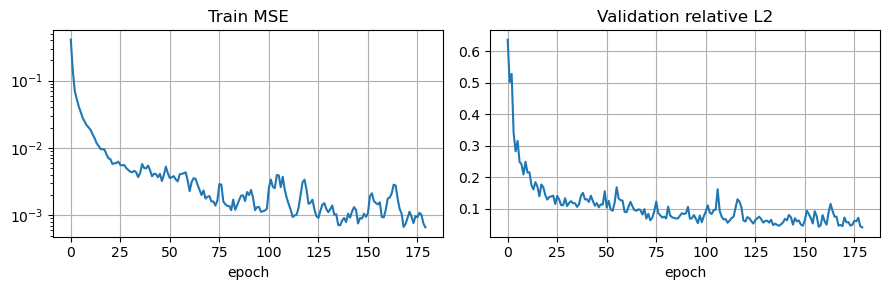

In [3]:
class GridMLP(nn.Module):
    def __init__(self,grid):
        super().__init__()
        n = len(grid)
        self.net = nn.Sequential(nn.Linear(n,64),nn.Tanh(),
                                 nn.Linear(64,64),nn.Tanh(),nn.Linear(64,n))
        self.register_buffer("boundary",4*grid*(1-grid))
    def forward(self,f):
        return self.net(f)*self.boundary

model = GridMLP(x)
print("parameters:",sum(p.numel() for p in model.parameters()))
history = fit(model,ftrain,vtrain,fval,vval,steps=epochs(180))
plot_history(history)

## 3. 用完全未见的函数测试

不能只看训练损失。恢复物理量后展示预测曲线、误差分布和边界误差。相对误差不随统一缩放改变。默认训练是教学规模，数值结果以实际运行输出为准。

Test relative L2: mean=0.0569, median=0.0469, max=0.2174


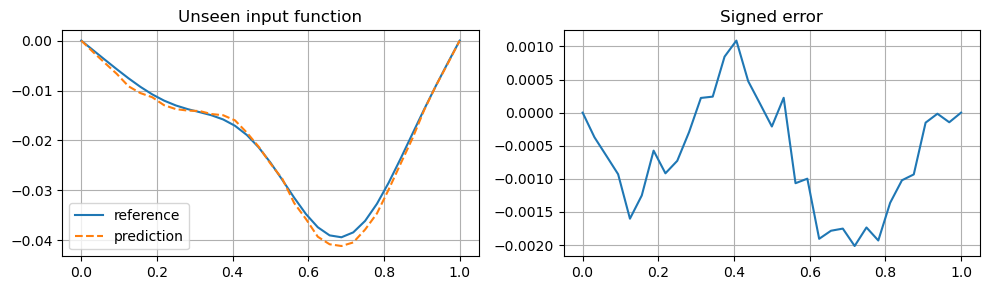

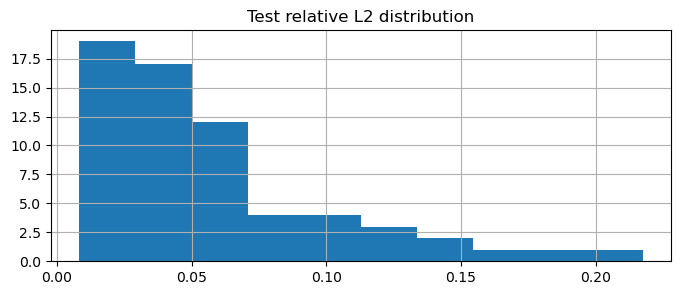

boundary max error: 0.0


In [4]:
pred,error = report(model,ftest,vtest)
plot_1d(x,vtest/torch.pi**2,pred/torch.pi**2)
plt.hist(error.numpy(),bins=10); plt.title("Test relative L2 distribution"); plt.show()
assert pred[:,[0,-1]].abs().max()<1e-7
print("boundary max error:",pred[:,[0,-1]].abs().max().item())

## 4. 分布外输入

增大频率带宽到 10，保持坐标和网络不变。与同分布测试比较，才能区分“见过类似函数”和“处理更复杂 forcing”。这里只是一次实验，不预设误差必然增大。

Test relative L2: mean=1.1998, median=0.7907, max=7.2788


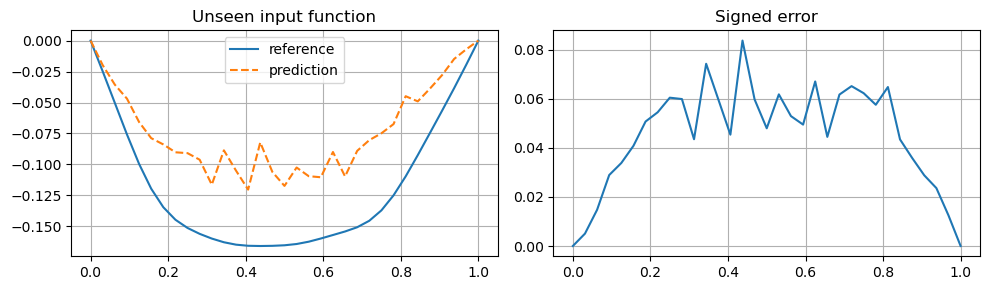

in-distribution mean: 0.05691494420170784 OOD mean: 1.199778437614441


In [5]:
ood_a = torch.randn(ntest,10)
ood_f,ood_v = poisson_data(ood_a,x)
ood_pred,ood_error = report(model,ood_f,ood_v)
plot_1d(x,ood_v/torch.pi**2,ood_pred/torch.pi**2)
print("in-distribution mean:",error.mean().item(),"OOD mean:",ood_error.mean().item())

**练习：** ① 改成纯线性层，比较线性 PDE 上的效率；② 去掉边界因子观察端点误差；③ 尝试把输入网格改为 65 点并解释 shape 错误。下一章将解耦输入传感器和输出查询点。